In [9]:
# Load data and median-fill missing values (temporary working copy for outlier detection)

import pandas as pd
import numpy as np

X_train = pd.read_csv("X_train.csv", index_col="id")
y_train = pd.read_csv("y_train.csv", index_col="id")["y"]
X_test  = pd.read_csv("X_test.csv",  index_col="id")

# medians from the training set only, used for both sets
train_medians = X_train.median()
X_train_med = X_train.fillna(train_medians)
X_test_med  = X_test.fillna(train_medians)

# check
for name, raw, filled in [("train", X_train, X_train_med), ("test", X_test, X_test_med)]:
    print(f"{name:5s}: shape {raw.shape} | missing {raw.isna().sum().sum()} ({raw.isna().mean().mean():.1%})"
          f" -> after fill {filled.isna().sum().sum()}")


train: shape (1212, 832) | missing 76902 (7.6%) -> after fill 0
test : shape (776, 832) | missing 40634 (6.3%) -> after fill 0


In [10]:
# Check & drop constant columns (found on the training set, dropped from both sets)

n_unique = X_train_med.nunique()
constant_cols = n_unique[n_unique <= 1].index

print(n_unique.describe())                      # min / median / max unique values per column
print("constant columns:", list(constant_cols))

X_train     = X_train.drop(columns=constant_cols)
X_train_med = X_train_med.drop(columns=constant_cols)
X_test      = X_test.drop(columns=constant_cols)
X_test_med  = X_test_med.drop(columns=constant_cols)
print("train:", X_train.shape, "| test:", X_test.shape)


count     832.000000
mean     1113.890625
std        81.378578
min         1.000000
25%      1113.000000
50%      1119.000000
75%      1125.000000
max      1147.000000
dtype: float64
constant columns: ['x104', 'x129', 'x489', 'x530']
train: (1212, 828) | test: (776, 828)


train variance explained by PC1-PC3: [0.139 0.061 0.043]


,train,test,test / train
PC1,72.91,50.29,0.69
PC2,32.04,20.85,0.65
PC3,22.67,22.17,0.98


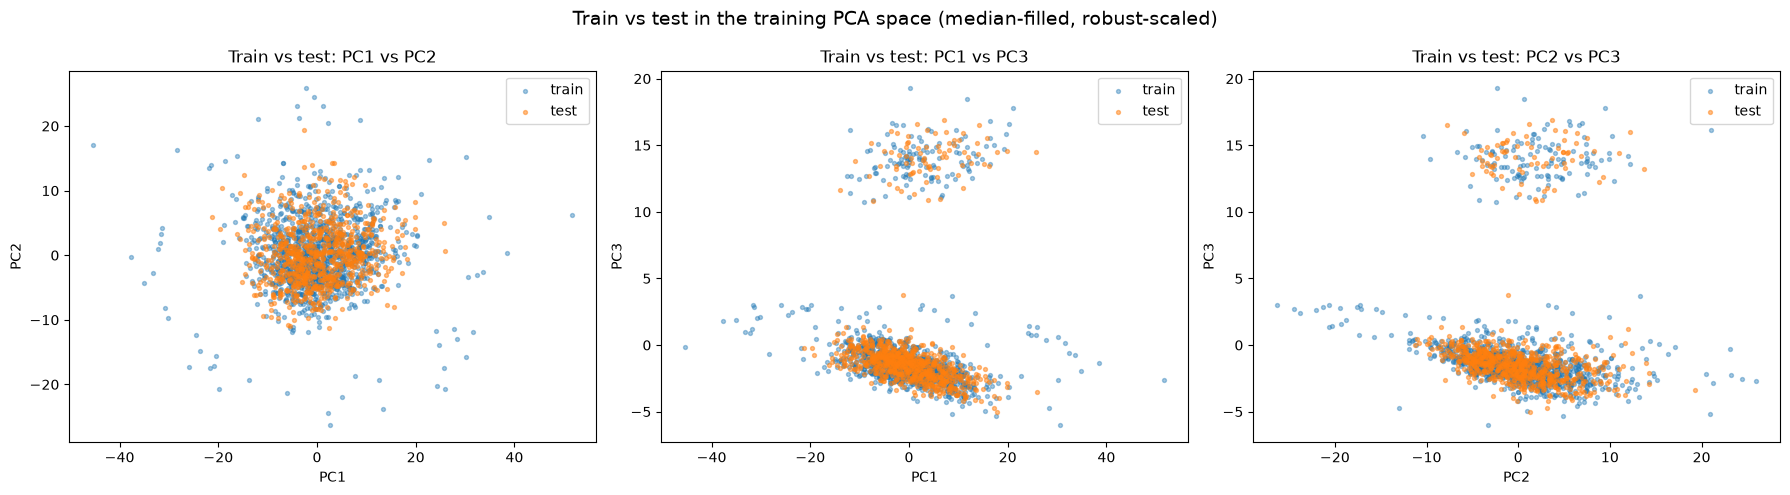

In [13]:
# Overview: train vs test on the first three principal components

from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import plotly.express as px

# scaler and PCA fitted on train only; test projected into the same space
scaler = RobustScaler().fit(X_train_med)
pca = PCA(n_components=3, random_state=0).fit(scaler.transform(X_train_med))
P_train = pca.transform(scaler.transform(X_train_med))
P_test  = pca.transform(scaler.transform(X_test_med))

# variance of each set along the training PCs (test / train < 1: test is less spread out along that PC)
var_table = pd.DataFrame({"train": P_train.var(axis=0), "test": P_test.var(axis=0)},
                         index=["PC1", "PC2", "PC3"])
var_table["test / train"] = var_table["test"] / var_table["train"]
print("train variance explained by PC1-PC3:", pca.explained_variance_ratio_.round(3))
display(var_table.round(2))

# 2D: each pair of PCs
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (i, j) in zip(axes, [(0, 1), (0, 2), (1, 2)]):
    ax.scatter(P_train[:, i], P_train[:, j], s=8, alpha=0.4, label="train")
    ax.scatter(P_test[:, i], P_test[:, j], s=8, alpha=0.5, label="test")
    ax.set_xlabel(f"PC{i + 1}"); ax.set_ylabel(f"PC{j + 1}"); ax.legend()
    ax.set_title(f"Train vs test: PC{i + 1} vs PC{j + 1}")
fig.suptitle("Train vs test in the training PCA space (median-filled, robust-scaled)", fontsize=14)
plt.tight_layout()
plt.show()

# 3D: interactive (drag to rotate, scroll to zoom)
df_3d = pd.DataFrame(np.vstack([P_train, P_test]), columns=["PC1", "PC2", "PC3"])
df_3d["set"] = ["train"] * len(P_train) + ["test"] * len(P_test)
fig = px.scatter_3d(df_3d, x="PC1", y="PC2", z="PC3", color="set", opacity=0.5,
                    color_discrete_map={"train": "royalblue", "test": "orange"},
                    title="Train vs test on PC1-PC3 (interactive)")
fig.update_traces(marker=dict(size=2))
fig.show()


In [21]:
# Outlier frameworks (1/3): every combination of scaler, PC space, detector and cut-off rule

from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.covariance import MinCovDet
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.svm import OneClassSVM

SCALERS   = {"robust": RobustScaler, "standard": StandardScaler}
SPACES    = [2, 3]                                   # number of PCs
DETECTORS = ["distance", "robust covariance", "iforest", "lof", "ocsvm", "knn to test"]
RULES     = ["test max", "test 99.5%", "test 99%", "test 98%", "2%", "3%", "4%", "5%", "6%"]

def fit_detector(Z, Z_te, detector):
    # returns (train scores, test scores, scorer for new points); higher = more anomalous
    med = np.median(Z, axis=0)
    mad = 1.4826 * np.median(np.abs(Z - med), axis=0)
    if detector == "distance":
        f = lambda X: np.sqrt((((X - med) / mad) ** 2).sum(axis=1))
    elif detector == "robust covariance":
        mcd = MinCovDet(random_state=0).fit(Z)
        f = lambda X: np.sqrt(mcd.mahalanobis(X))
    elif detector == "iforest":
        iso = IsolationForest(n_estimators=300, random_state=0).fit(Z)
        f = lambda X: -iso.score_samples(X)
    elif detector == "lof":
        lof = LocalOutlierFactor(n_neighbors=20, novelty=True).fit(Z)
        f = lambda X: -lof.score_samples(X)
        return -lof.negative_outlier_factor_, f(Z_te), f   # train rows: left out of their own neighborhood
    elif detector == "ocsvm":
        svm = OneClassSVM(kernel="rbf", gamma="scale", nu=0.05).fit(Z)
        f = lambda X: -svm.decision_function(X)
    elif detector == "knn to test":
        # distance to the 5th nearest test row, each PC scaled by its MAD so PC3 isn't ignored
        nn = NearestNeighbors(n_neighbors=6).fit((Z_te - med) / mad)
        f = lambda X: nn.kneighbors((X - med) / mad, n_neighbors=5)[0][:, 4]
        return f(Z), nn.kneighbors((Z_te - med) / mad)[0][:, 5], f   # test rows: 5th nearest *other* test row
    return f(Z), f(Z_te), f

def cut_off(a_tr, a_te, rule):
    # "test max": furthest test row | "test q%": q% of test rows inside | "x%": remove the top x% of training rows
    if rule == "test max":
        return a_te.max()
    if rule.startswith("test "):
        return np.quantile(a_te, float(rule[5:-1]) / 100)
    return np.quantile(a_tr, 1 - float(rule[:-1]) / 100)

frameworks = {"no removal": dict(scaler="-", space="-", detector="-", rule="-", cut=None, test_beyond=0,
                                 keep=np.ones(len(X_train_med), dtype=bool))}
views, scorers = {}, {}   # PC view per scaler and fitted scorer per (scaler, space, detector), reused in the next cells

for s_name, Scaler in SCALERS.items():
    sc = Scaler().fit(X_train_med)
    pca = PCA(n_components=max(SPACES), svd_solver="full").fit(sc.transform(X_train_med))
    P_tr, P_te = pca.transform(sc.transform(X_train_med)), pca.transform(sc.transform(X_test_med))
    views[s_name] = (P_tr, P_te)

    for space in SPACES:
        for det in DETECTORS:
            a_tr, a_te, scorers[(s_name, space, det)] = fit_detector(P_tr[:, :space], P_te[:, :space], det)
            for rule in RULES:
                cut = cut_off(a_tr, a_te, rule)
                frameworks[f"{s_name} | {space} PCs | {det} | {rule}"] = dict(
                    scaler=s_name, space=space, detector=det, rule=rule, cut=cut,
                    test_beyond=int((a_te > cut).sum()), keep=a_tr <= cut)

print(len(frameworks), "frameworks")


217 frameworks


In [22]:
# Outlier frameworks (2/2): rank every framework by precision / recall against the test set

from sklearn.metrics import pairwise_distances

# fixed evaluation space: the robust-scaled 3-PC view (needs 3 in SPACES), each PC scaled by its MAD
E_tr, E_te = views["robust"]
med = np.median(E_tr, axis=0)
mad = 1.4826 * np.median(np.abs(E_tr - med), axis=0)
E_tr, E_te = (E_tr - med) / mad, (E_te - med) / mad

K = 5
r_te = NearestNeighbors(n_neighbors=K + 1).fit(E_te).kneighbors(E_te)[0][:, K]   # each test row's neighborhood radius
D = pairwise_distances(E_tr, E_te)                                                # train x test distances, once

def precision_recall(keep):
    # precision: share of kept training rows inside the neighborhood of at least one test row
    # recall:    share of test rows inside the neighborhood of at least one kept training row
    A = E_tr[keep]
    r_tr = NearestNeighbors(n_neighbors=K + 1).fit(A).kneighbors(A)[0][:, K]
    Dk = D[keep]
    return (Dk <= r_te[None, :]).any(axis=1).mean(), (Dk <= r_tr[:, None]).any(axis=0).mean()

rows = []
for name, fw in frameworks.items():
    precision, recall = precision_recall(fw["keep"])
    rows.append({"framework": name, "scaler": fw["scaler"], "PCs": fw["space"], "detector": fw["detector"],
                 "rule": fw["rule"], "removed": int((~fw["keep"]).sum()), "test beyond cut": fw["test_beyond"],
                 "precision": precision, "recall": recall})
res = pd.DataFrame(rows)

# rank: recall within 0.005 of no removal first, then highest precision, then fewest rows removed
res["recall ok"] = res["recall"] >= res.loc[res["framework"] == "no removal", "recall"].iloc[0] - 0.005
res = res.sort_values(["recall ok", "precision", "removed"], ascending=[False, False, True]).reset_index(drop=True)

chosen = res.loc[0, "framework"]
print("chosen:", chosen)
display(pd.concat([res.head(5), res[res["framework"] == "no removal"]]).drop(columns="framework").round(4))


chosen: robust | 3 PCs | knn to test | test 99.5%


,scaler,PCs,detector,rule,removed,test beyond cut,precision,recall,recall ok
0,robust,3,knn to test,test 99.5%,60,4,0.9922,0.9871,True
1,standard,2,distance,5%,61,9,0.9896,0.9871,True
2,robust,2,distance,test 99.5%,57,4,0.9887,0.9871,True
3,robust,2,robust covariance,test 99.5%,57,4,0.9887,0.9871,True
4,robust,2,iforest,test 99.5%,57,4,0.9887,0.9871,True
145,-,-,-,-,0,0,0.9497,0.9910,True


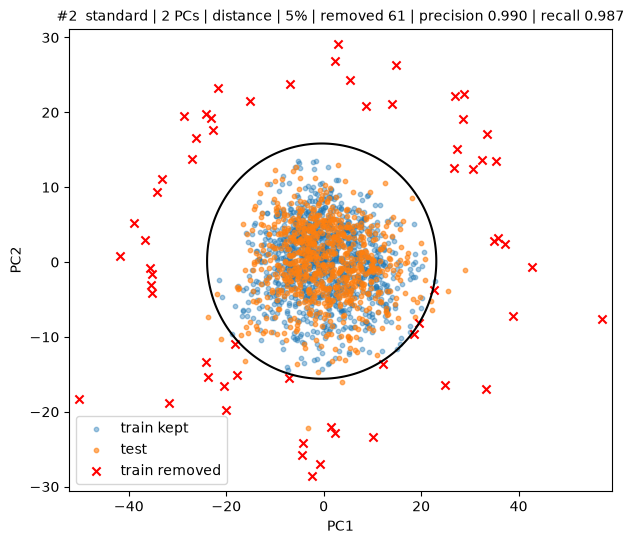

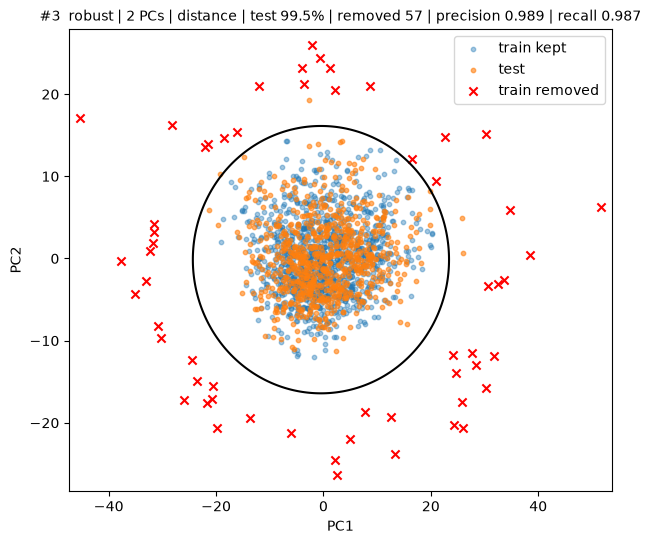

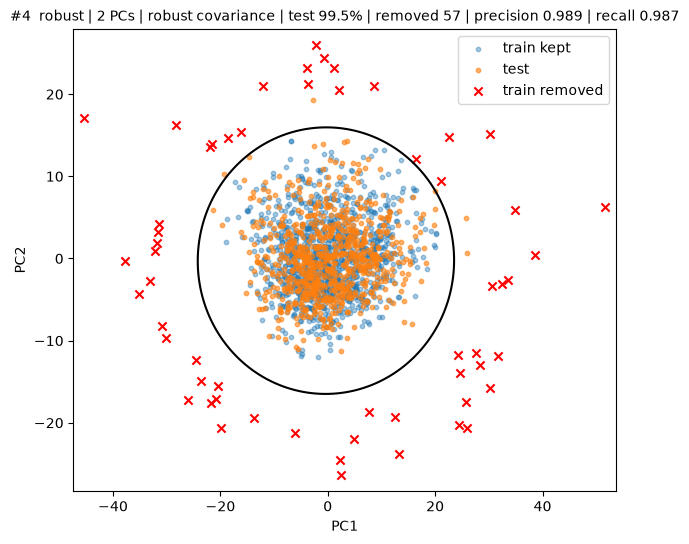

In [24]:
# Visualization: top 4 frameworks in their detection space (2D with exact border, 3D interactive with border surface)

import plotly.graph_objects as go

for rank, row in res[res["framework"] != "no removal"].head(4).iterrows():
    fw = frameworks[row["framework"]]
    k, keep = fw["space"], fw["keep"]
    P_tr, P_te = (P[:, :k] for P in views[fw["scaler"]])
    title = (f"#{rank + 1}  {row['framework']} | removed {row['removed']} | "
             f"precision {row['precision']:.3f} | recall {row['recall']:.3f}")

    # border = where the detector's score equals the framework's cut-off, evaluated on a grid
    P_all = np.vstack([P_tr, P_te])
    grid = np.meshgrid(*[np.linspace(lo - 2, hi + 2, 250 if k == 2 else 40)
                         for lo, hi in zip(P_all.min(axis=0), P_all.max(axis=0))], indexing="ij")
    g = scorers[(fw["scaler"], k, fw["detector"])](np.column_stack([a.ravel() for a in grid])).reshape(grid[0].shape)

    if k == 2:
        plt.figure(figsize=(7, 6))
        plt.contour(grid[0], grid[1], g, levels=[fw["cut"]], colors="black")
        plt.scatter(*P_tr[keep].T, s=10, alpha=0.4, label="train kept")
        plt.scatter(*P_te.T, s=10, alpha=0.6, label="test")
        plt.scatter(*P_tr[~keep].T, c="red", marker="x", s=35, label="train removed")
        plt.xlabel("PC1"); plt.ylabel("PC2"); plt.legend(); plt.title(title, fontsize=10)
        plt.show()
    else:
        points = [(P_tr[keep], "train kept", "royalblue", 2, 0.4, "circle"),
                  (P_te, "test", "orange", 2, 0.6, "circle"),
                  (P_tr[~keep], "train removed", "red", 4, 1.0, "x")]
        fig = go.Figure(
            [go.Isosurface(x=grid[0].ravel(), y=grid[1].ravel(), z=grid[2].ravel(), value=g.ravel(),
                           isomin=fw["cut"], isomax=fw["cut"], surface_count=1, opacity=0.15,
                           colorscale=[[0, "grey"], [1, "grey"]], showscale=False,
                           caps=dict(x_show=False, y_show=False, z_show=False), name="border", showlegend=True)]
            + [go.Scatter3d(x=P[:, 0], y=P[:, 1], z=P[:, 2], mode="markers", name=name,
                            marker=dict(size=size, color=color, opacity=opacity, symbol=symbol))
               for P, name, color, size, opacity, symbol in points])
        fig.update_layout(title=title, height=700, scene=dict(xaxis_title="PC1", yaxis_title="PC2", zaxis_title="PC3"))
        fig.show()


In [8]:
# Outlier removal: apply the chosen framework

keep = frameworks[chosen]["keep"]
X_train_in     = X_train[keep]       # original values with NaNs (for the final kNN step)
X_train_med_in = X_train_med[keep]   # median-filled (for feature selection)
y_train_in     = y_train[keep]
print(f"{chosen}: removed {(~keep).sum()} of {len(keep)} rows")
print(X_train_in.shape, X_train_med_in.shape, y_train_in.shape)


robust | 3 PCs | knn to test | test 99.5%: removed 60 of 1212 rows
(1152, 828) (1152, 828) (1152,)
